In [1]:
import pandas as pd

# LOAD Labeled_Data_for_Exclusion_Included

In [2]:

output_file = "Labeled_Data_for_Exclusion_Included.csv"
processed_df = pd.read_csv(output_file)
processed_df

,PubMed ID,DOI,Title,Year,Abstract,Author Keywords,english,Decision
0,16985399.0,10.1097/00001786-200610000-00006,Missed nursing care: a qualitative study,2006,The purpose of this study was to determine nur...,[],en,Excluded\n\nExplain: The title and abstract of...
1,15946170.0,10.1111/j.1365-2934.2005.00541.x,Confirming mentorship,2005,Mentorship is related to nurses' success in nu...,[],en,**Decision:** Excluded\n\n**Explanation:** \n\...
2,17147757.0,10.1111/j.1741-6787.2004.04008.x,Methods in translation science,2004,The gap between research findings and practice...,[],en,**Decision:** Excluded\n\n**Explanation:** \nT...
3,19076465.0,10.1111/j.1744-6198.2008.00115.x,Competency: a concept analysis,2008,Concept analysis of competency.\nThe purpose o...,[],en,Decision: excluded\n\nExplain: The abstract in...
4,15946274.0,10.1111/j.1365-2702.2005.01136.x,Clinical education facilitators: a literature ...,2005,"The aim of this literature review, set within ...",[],en,Excluded\n\nExplain: The abstract of the paper...
...,...,...,...,...,...,...,...,...
17203,35332562.0,10.1111/jan.15219,What the curtains do not shield: A phenomenolo...,2022,Aims: To explore healthcare professionals' exp...,cardiac arrest; cardiopulmonary resuscitation;...,en,**Decision:** Excluded\n\n**Explain:** \nThe ...
17204,31666038.0,10.1186/s12904-019-0481-y,End-of-life and palliative care of patients on...,2019,Background: Despite complex illness trajectori...,End-of-life care; Palliative care; End-stage k...,en,**Decision:** Excluded\n\n**Explanation:** \n...
17205,38287332.0,10.1186/s12913-024-10617-9,The Quality in Acute Stroke Care (QASC) global...,2024,BackgroundVariation in hospital stroke care is...,Implementation science; Facilitation; Stroke; ...,en,**Decision:** Excluded\n\n**Explanation:** \n\...
17206,38877433.0,10.1186/s12877-024-05124-9,Exploring the impact of pharmacist-supported m...,2024,Background Dementia is a major global public h...,Clinical pharmacy; Collaboration; Dementia; Dr...,en,**Decision:** Excluded\n\n**Explanation:** The...


In [2]:
import re

# Define a function to extract "Inclusion" or "Exclusion" from the Decision column
def extract_decision(decision_text):
    decision_text = str(decision_text)
    match = re.search(r'\b(Inclusion|Exclusion|Included|Excluded)\b', decision_text, re.IGNORECASE)
    if match:
        return match.group(0).capitalize()  # Capitalize to maintain consistency (e.g., "Excluded")
    return "Unknown"  # Return "Unknown" if no match is found

# Apply the function to the Decision column
processed_df['Decision Type'] = processed_df['Decision'].apply(extract_decision)

# Display the DataFrame with the extracted decision type
print(processed_df[['Decision', 'Decision Type']].head())


                                            Decision Decision Type
0  Excluded\n\nExplain: The title and abstract of...      Excluded
1  **Decision:** Excluded\n\n**Explanation:** \n\...      Excluded
2  **Decision:** Excluded\n\n**Explanation:** \nT...      Excluded
3  Decision: excluded\n\nExplain: The abstract in...      Excluded
4  Excluded\n\nExplain: The abstract of the paper...      Excluded


In [17]:
filter_data = processed_df[(processed_df['Decision Type'] == 'Included') | (processed_df['Decision Type'] == 'Inclusion')]

# Checking if it is a review study

In [52]:
ip_port = "132.72.66.154:9982"
url = f"http://{ip_port}/api/generate"


In [53]:
import json
import pandas as pd
import requests

def extract_full_text(response_text):
    """
    This function extracts and concatenates text from the 'response' field in each JSON line of the response.
    
    Parameters:
    response_text (str): The raw response text, with each line being a JSON string.

    Returns:
    str: The concatenated text from all 'response' fields.
    """
    full_text = ""  # Variable to store the complete text
    
    # Iterate over each line in the response
    for line in response_text.text.splitlines():
        try:
            data = json.loads(line)  # Parse each JSON line
            if "response" in data:  # Check if the "response" field exists
                full_text += data["response"]  # Append the text
        except json.JSONDecodeError:
            print("Unable to parse line:", line)
    
    return full_text

In [79]:

def check_type(abstract,title):
    prompt = (
        "You will receive a title and an abstract. Your task is to determine the type of review described by the provided information."
        "If the research is a review type (e.g., systematic review, scoping review, meta-analysis), return 0."
        "If the research describes other types of research, return 1."
        "If the type of research cannot be determined from the provided information, return 2. \n\n"
        f"Title: {title}\n"
        f"Abstract: {abstract}\n\n"
        "Decision: {Write the decision here (only number)}"
        "Explain: {Here}"
        
    )
    
    payload = {
        "model": "phi4",
        "prompt": prompt,
        "temperature": 0.2,  
        "top_p": 0.2       
    }

    # Make a POST request
    response = requests.post(url, json=payload)

    # Validate the response
    if response.status_code == 200:
        # decision = response.json().get("choices", [{}])[0].get("text", "").strip()
        decision = extract_full_text(response)
        # print(decision)
        # print("------------------------------------------------")
        return decision #if decision in {"included", "excluded"} else decision
    else:
        print(f"Error: {response.status_code} - {response.text}")
        return None

In [141]:

def check_type(abstract,title):
    prompt = (
        "You will receive a title and an abstract. Your task is to determine the type of review described by the provided information."
        "If the research is a review type (e.g., systematic review, scoping review, meta-analysis), return 0."
        "If the research describes other types of research, return 1."
        "If the type of research cannot be determined from the provided information, return 2. \n\n"
        f"Title: {title}\n"
        f"Abstract: {abstract}\n\n"
        "Write according to the following template:"
        "Decision: {Write the decision here (only number 0,1,2)}"
        "Do not add additional comments."
        
    )
    
    payload = {
        "model": "phi4",
        "prompt": prompt,
        "temperature": 0.2,  
        "top_p": 0.2       
    }

    # Make a POST request
    response = requests.post(url, json=payload)

    # Validate the response
    if response.status_code == 200:
        # decision = response.json().get("choices", [{}])[0].get("text", "").strip()
        decision = extract_full_text(response)
        # print(decision)
        # print("------------------------------------------------")
        return decision #if decision in {"included", "excluded"} else decision
    else:
        print(f"Error: {response.status_code} - {response.text}")
        return None

In [22]:
from tqdm import tqdm

# Define a function to process each row and update the CSV incrementally
def add_decision_column_and_save(df, output_file):
    # Check if the file already exists
    import os
    if os.path.exists(output_file):
        # If the file exists, load it
        processed_df = pd.read_csv(output_file)
        start_index = len(processed_df)  # Start from where we left off
    else:
        # If the file doesn't exist, initialize an empty DataFrame
        processed_df = pd.DataFrame(columns=df.columns.tolist() + ['Type_article'])
        start_index = 0

    # Iterate over rows with tqdm for progress tracking, starting from the last processed row
    for i in tqdm(range(start_index, len(df)), desc="Processing rows"):
        # Extract abstract and title for each row
        abstract = df.iloc[i].Abstract
        title = df.iloc[i].Title
        
        # Call the check_relevance function
        decision = check_type(abstract, title)
        
        # Add the current row and decision to the processed DataFrame
        current_row = df.iloc[i].to_dict()
        current_row['Type_article'] = decision
        processed_df = pd.concat([processed_df, pd.DataFrame([current_row])], ignore_index=True)
        
        # Save the updated DataFrame to the CSV file after each iteration
        processed_df.to_csv(output_file, index=False)

    return processed_df


# File to save the updated DataFrame
output_file = "updated_decisions_incremental_Type_article.csv"

# Call the function with your DataFrame
df_with_decisions = add_decision_column_and_save(filter_data, output_file)

# Display the first few rows of the final DataFrame
print(df_with_decisions.head())


Processing rows:   0%|          | 0/722 [00:00<?, ?it/s]/tmp/ipykernel_3941164/3636865163.py:28: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  processed_df = pd.concat([processed_df, pd.DataFrame([current_row])], ignore_index=True)
Processing rows: 100%|██████████| 722/722 [36:33<00:00,  3.04s/it]

    PubMed ID                                 DOI  \
0   7567566.0                                 NaN   
1  17100863.0    10.1111/j.1365-2753.2006.00632.x   
2  12470013.0           10.1016/s0964339702000125   
3  18838895.0  10.1097/01.NND.0000320688.57308.f9   
4  15913267.0                                 NaN   

                                               Title  Year  \
0  Barriers and facilitators of research utilizat...  1995   
1  Research utilization and clinical nurse educat...  2006   
2  Barriers to research utilisation: the clinical...  2002   
3  Nursing faculty mentors as facilitators for ev...  2008   
4  Barriers to implementing research in clinical ...  2005   

                                            Abstract Author Keywords english  \
0  For over 20 years, nursing literature has disc...              []      en   
1  Clinical nurse educators and other linking age...              []      en   
2  The advance of the evidence-based practice (EB...              []

In [31]:
import pandas as pd

df_with_decisions= pd.read_csv('updated_decisions_incremental_Type_article.csv')

df_with_decisions

,PubMed ID,DOI,Title,Year,Abstract,Author Keywords,english,Decision,Decision Type,Type_article
0,7567566.0,NaN,Barriers and facilitators of research utilizat...,1995,"For over 20 years, nursing literature has disc...",[],en,**Decision:** included\n\n**Explanation:** \n\...,Included,**Decision:** 0\n\n**Explanation:** The title ...
1,17100863.0,10.1111/j.1365-2753.2006.00632.x,Research utilization and clinical nurse educat...,2006,Clinical nurse educators and other linking age...,[],en,**Included**\n\n**Explanation:**\n- **Inclusio...,Included,**Decision:** 0\n\n**Explanation:** The title ...
2,12470013.0,10.1016/s0964339702000125,Barriers to research utilisation: the clinical...,2002,The advance of the evidence-based practice (EB...,[],en,**Decision:** included\n\n**Explain:** \n\nThe...,Included,**Decision:** 1\n\n**Explanation:** The abstra...
3,18838895.0,10.1097/01.NND.0000320688.57308.f9,Nursing faculty mentors as facilitators for ev...,2008,Increasing use of evidence-based practice (EBP...,[],en,Included\n\nExplain: \n\nThe abstract of the p...,Included,Decision: 1\n\nExplanation: The abstract descr...
4,15913267.0,NaN,Barriers to implementing research in clinical ...,2005,Barriers to implementing research in clinical ...,[],en,**Included**\n\n**Explanation:** \nThe title ...,Included,**Decision:** 0\n\n**Explanation:** The abstra...
...,...,...,...,...,...,...,...,...,...,...
717,22967300.0,10.1111/j.1365-2834.2012.01473.x,Clinical nurses' research capacity in a Norweg...,2012,Aim To examine clinical nurses' research capac...,clinical nurses; competence; research capacity...,en,**Decision:** Included\n\n**Explain:** \n\nThe...,Included,**Decision:** 1\n\n**Explanation:** The abstra...
718,NaN,10.14744/etd.2020.01205,An Academic-Clinical Partnership Project: The ...,2020,Objective: The present study aims to reveal th...,Nurse; scientific research; educational program,en,**Decision:** Included\n\n**Explanation:** \n\...,Included,**Decision:** 1\n\n**Explanation:** The provid...
719,36511161.0,10.7748/nr.2022.e1863,The improvement in research orientation among ...,2023,Background The main barrier to engaging nurses...,best practice; career development; organisatio...,en,**Decision:** Included\n\n**Explain:** \n\n- *...,Included,Decision: 1\n\nExplain: The title explicitly s...
720,26422084.0,10.1111/wvn.12106,The Effectiveness of Interventions for Improvi...,2015,"BackgroundInternationally, a considerable body...",systematic review; research literacy; interven...,en,**Decision:** Included\n\n**Explanation:** \n\...,Included,**Decision:** 0\n\n**Explanation:** The provid...


In [122]:
check_type(df_with_decisions.iloc[0]["Title"], df_with_decisions.iloc[0]["Abstract"])

'Decision: 0'

In [27]:
# df_with_decisions["Extracted_Number"] = df_with_decisions["Type_article"].str.extract(r'(?:\*\*Decision:\*\*|Decision:) (\d+)')
# df_with_decisions

,PubMed ID,DOI,Title,Year,Abstract,Author Keywords,english,Decision,Decision Type,Type_article,Extracted_Number
0,7567566.0,NaN,Barriers and facilitators of research utilizat...,1995,"For over 20 years, nursing literature has disc...",[],en,**Decision:** included\n\n**Explanation:** \n\...,Included,**Decision:** 0\n\n**Explanation:** The title ...,0
1,17100863.0,10.1111/j.1365-2753.2006.00632.x,Research utilization and clinical nurse educat...,2006,Clinical nurse educators and other linking age...,[],en,**Included**\n\n**Explanation:**\n- **Inclusio...,Included,**Decision:** 0\n\n**Explanation:** The title ...,0
2,12470013.0,10.1016/s0964339702000125,Barriers to research utilisation: the clinical...,2002,The advance of the evidence-based practice (EB...,[],en,**Decision:** included\n\n**Explain:** \n\nThe...,Included,**Decision:** 1\n\n**Explanation:** The abstra...,1
3,18838895.0,10.1097/01.NND.0000320688.57308.f9,Nursing faculty mentors as facilitators for ev...,2008,Increasing use of evidence-based practice (EBP...,[],en,Included\n\nExplain: \n\nThe abstract of the p...,Included,Decision: 1\n\nExplanation: The abstract descr...,1
4,15913267.0,NaN,Barriers to implementing research in clinical ...,2005,Barriers to implementing research in clinical ...,[],en,**Included**\n\n**Explanation:** \nThe title ...,Included,**Decision:** 0\n\n**Explanation:** The abstra...,0
...,...,...,...,...,...,...,...,...,...,...,...
717,22967300.0,10.1111/j.1365-2834.2012.01473.x,Clinical nurses' research capacity in a Norweg...,2012,Aim To examine clinical nurses' research capac...,clinical nurses; competence; research capacity...,en,**Decision:** Included\n\n**Explain:** \n\nThe...,Included,**Decision:** 1\n\n**Explanation:** The abstra...,1
718,NaN,10.14744/etd.2020.01205,An Academic-Clinical Partnership Project: The ...,2020,Objective: The present study aims to reveal th...,Nurse; scientific research; educational program,en,**Decision:** Included\n\n**Explanation:** \n\...,Included,**Decision:** 1\n\n**Explanation:** The provid...,1
719,36511161.0,10.7748/nr.2022.e1863,The improvement in research orientation among ...,2023,Background The main barrier to engaging nurses...,best practice; career development; organisatio...,en,**Decision:** Included\n\n**Explain:** \n\n- *...,Included,Decision: 1\n\nExplain: The title explicitly s...,1
720,26422084.0,10.1111/wvn.12106,The Effectiveness of Interventions for Improvi...,2015,"BackgroundInternationally, a considerable body...",systematic review; research literacy; interven...,en,**Decision:** Included\n\n**Explanation:** \n\...,Included,**Decision:** 0\n\n**Explanation:** The provid...,0


In [133]:
from tqdm import tqdm



df_with_decisions["Extracted_Number"] = df_with_decisions["Type_article"].str.extract(r'(?:\*\*Decision:\*\*|Decision:)\s*(\d+)')
# missing_values = df_with_decisions["Extracted_Number"].isnull()
condition = (df_with_decisions['Extracted_Number'] != '0') & (df_with_decisions['Extracted_Number'] != '1')

# Update the 'Type_article' column for rows matching the condition
df_with_decisions.loc[condition, "Type_article"] = df_with_decisions.loc[condition].apply(
    lambda row: check_type(row["Title"], row["Abstract"]), axis=1
)

# df_with_decisions.loc[missing_values, "Type_article"] = df_with_decisions.loc[missing_values].apply(
#     lambda row: check_type(row["Title"], row["Abstract"]), axis=1
# )
# df_with_decisions["Extracted_Number"] = df_with_decisions["Type_article"].str.extract(r'(?:\*\*Decision:\*\*|Decision:)\s*(\d+)')

# Define a regex pattern to extract numbers after '**Decision**:' or 'Decision:'
pattern = r'(?:(?:\*\*Decision\*\*)|Decision):\s*(\d+)\.'
pattern = r"(?:(?:\*\*Decision\*\*)|Decision):\s*(\d+)"

# Apply the regex to the 'Type_article' column where 'Extracted_Number' is missing
missing_values = df_with_decisions["Extracted_Number"].isnull()
df_with_decisions.loc[missing_values, "Extracted_Number"] = (
    df_with_decisions.loc[missing_values, "Type_article"]
    .dropna()  
    .str.extract(pattern)[0]  
)

# df_with_decisions.loc[missing_values, "Extracted_Number"] = df_with_decisions.loc[missing_values, "Type_article"].str.extract(r'(?:(?:\*\*Decision\*\*)|Decision):\s*(\d+)')








In [138]:
sys = df_with_decisions[(df_with_decisions['Extracted_Number'] != '0') & (df_with_decisions['Extracted_Number'] != '1')]
sys

,PubMed ID,DOI,Title,Year,Abstract,Author Keywords,english,Decision,Decision Type,Type_article,Extracted_Number
419,27409075.0,10.1186/s12913-016-1423-5,Proceedings of the 3rd IPLeiria's Internationa...,2016,S1 Health literacy and health education in ado...,[],en,To determine whether any of the articles liste...,Inclusion,The document you've provided is a list of abst...,NaN
421,27606392.0,NaN,Evidence Brief: The Quality of Care Provided b...,2014,P001 - Sepsis impairs the capillary response w...,[],en,To determine which articles should be included...,Included,The abstract provided does not directly corres...,451
424,36636019.0,10.1177/10748407221145963,Barriers and Facilitators Influencing Nurses' ...,2023,The term “Advanced Practice Registered Nurse” ...,NaN,en,The decision here is **Exclude** based on the ...,Inclusion,**Decision: 2**\n\nThe question presents a sce...,3


In [148]:
df_with_decisions.loc[419,'Extracted_Number'] = '2'
df_with_decisions.loc[421,'Extracted_Number'] = '1'
df_with_decisions.loc[424,'Extracted_Number'] = '2'

In [144]:
check_type(sys.iloc[0].Abstract,sys.iloc[0].Title)

'To determine which of the projects listed under "O" and "P" have a focus on health literacy:\n\n**Projects from "O":**\n\n- O248: Health education in people with coronary heart disease - involves health education but does not explicitly mention health literacy.\n- O249: Information and training needs of informal caregivers of individuals with stroke sequelae - relates to information needs, possibly linked to health literacy.\n- O250: Prevention of psychoactive substances consumption in students from 6th grade of Albergaria-a-Velha\'s School Group - focuses on prevention education but does not explicitly mention health literacy.\n- O251: Promoting healthy sexuality: shared responsibility for family, youth and educators - involves health promotion, potentially related to health literacy.\n- O252: Sexual risk behaviour in adolescents and young people - likely includes elements of health literacy as part of behavior understanding.\n- O253: Knowledge of school staff on type 1 diabetes - in

In [145]:
check_type(sys.iloc[1].Abstract,sys.iloc[1].Title)

"To determine which paper(s) discuss topics related to both end-of-life care and organ donation, let's analyze each entry:\n\n- **P447**: Discusses palliative care consultation in relation to ICU admission requests.\n- **P448**: Addresses prognostic conflicts at the end of life within a postsurgical ICU setting.\n- **P449**: Considers who makes decisions regarding the end of life.\n- **P450**: Involves skin procurement by intensive care physicians, relevant to organ donation.\n- **P451**: Analyzes death in pediatric intensive care patients.\n- **P452**: Examines the potential impact of euthanasia on organ donation.\n\nFrom this analysis:\n\n- **P452** directly links end-of-life decisions (euthanasia) with organ donation.\n- **P450** involves organ procurement, which can relate to end-of-life situations but does not explicitly mention end-of-life care in the description.\n\nThus, the paper that clearly discusses both topics is P452.\n\nDecision: 1"

In [143]:
check_type(sys.iloc[2].Abstract,sys.iloc[2].Title)

'Decision: 2\n\nThe text discusses various studies and perspectives on the role of Advanced Practice Registered Nurses (APRNs) in healthcare settings, particularly focusing on their ability to deliver care comparable to that provided by physicians when working autonomously or within integrated teams. The decision is based on several key findings:\n\n1. **Comparability in Care**: Multiple reviews, including those cited from sources like the Institute of Medicine and the Robert Wood Johnson Foundation (RWJF), support the idea that APRNs can provide care comparable to that provided by physicians in terms of safety, effectiveness, and efficiency.\n\n2. **Team-Based Models**: The emphasis on team-based care highlights how APRNs working alongside or under the supervision of physicians can achieve similar or sometimes better patient outcomes compared to physician-only care models. This is especially relevant in integrated primary care settings such as those found in the Veterans Health Admini

In [136]:
df_with_decisions.shape

(722, 11)

In [173]:
df_with_decisions["Extracted_Number"].value_counts()

Extracted_Number
1    642
0     78
2      2
Name: count, dtype: int64

In [174]:
df_with_decisions.to_csv("final_type.csv")

In [150]:
temp = df_with_decisions[df_with_decisions['Extracted_Number'] == '0']

In [153]:
temp

,PubMed ID,DOI,Title,Year,Abstract,Author Keywords,english,Decision,Decision Type,Type_article,Extracted_Number,Type_review
0,7567566.0,NaN,Barriers and facilitators of research utilizat...,1995,"For over 20 years, nursing literature has disc...",[],en,**Decision:** included\n\n**Explanation:** \n\...,Included,**Decision:** 0\n\n**Explanation:** The title ...,0,Integrative review
1,17100863.0,10.1111/j.1365-2753.2006.00632.x,Research utilization and clinical nurse educat...,2006,Clinical nurse educators and other linking age...,[],en,**Included**\n\n**Explanation:**\n- **Inclusio...,Included,**Decision:** 0\n\n**Explanation:** The title ...,0,systematic review
4,15913267.0,NaN,Barriers to implementing research in clinical ...,2005,Barriers to implementing research in clinical ...,[],en,**Included**\n\n**Explanation:** \nThe title ...,Included,**Decision:** 0\n\n**Explanation:** The abstra...,0,Review of literature (qualitative review)
13,10076245.0,10.1097/00002800-199811000-00009,Research utilization and the CNS: confronting ...,1998,Utilization of research in nursing is still in...,[],en,**Decision:** Included\n\n**Explanation:** \n\...,Included,**Decision:** 0\n\n**Explanation:** The abstra...,0,Literature review
75,8057184.0,10.1111/j.1552-6909.1994.tb01882.x,Research utilization: an overview,1994,"Nursing practice needs to be research based, n...",[],en,Included\n\nExplanation: The abstract indicate...,Included,**Decision:** 0\n\n**Explanation:** The title ...,0,Overview/Conceptual Review
...,...,...,...,...,...,...,...,...,...,...,...,...
695,10886435.0,10.1046/j.1365-2648.2000.01447.x,Developing the research capacity of department...,2000,The purpose of this literature review is to id...,nursing research; research capacity developmen...,en,**Decision:** included\n\n**Explanation:**\n\n...,Included,**Decision:** 0\n\n**Explanation:** The title ...,0,literature review
703,33783388.0,10.1097/ANC.0000000000000851,A Review of the NANN Research Summit Experienc...,2022,Background: The NANN Research Summit has been ...,clinical inquiry; mentorship; neonatal nurse; ...,en,**Decision:** included\n\n**Explanation:** \n\...,Included,**Decision:** 0\n\n**Explanation:** The title ...,0,Program evaluation or impact assessment review
715,34729898.0,10.1111/wvn.12542,The Experiences and Perceptions of Nurses Inte...,2021,Background There is an evidence that some nurs...,nurse education; research education; research ...,en,Included\n\n**Explanation:**\n\n1. **Inclusion...,Included,**Decision:** 0\n\n**Explanation:** The resear...,0,Qualitative Systematic Review
716,34820932.0,10.1111/jocn.16133,Mixed methods systematic review: Factors influ...,2022,"Aim This study aimed to identify, evaluate and...",barriers and enablers; conducting research; mi...,en,Included\n\n**Explanation:** \n\n- **Inclusion...,Included,**Decision:** 0\n\n**Explanation:** The provid...,0,Mixed methods systematic review


In [151]:

def check_type_review(abstract,title):

    prompt = (
        "You will receive a title and an abstract. Your task is to determine the type of review described by the provided information. "
        "Provide only the type of review as the output (e.g., systematic review, scoping review, meta-analysis, etc.). Do not include an explanation.\n\n"
        f"Title: {title}\n"
        f"Abstract: {abstract}\n\n"
        "Review type:"
    )
    
    payload = {
        "model": "phi4",
        "prompt": prompt,
        "temperature": 0.2,  
        "top_p": 0.2       
    }

    # Make a POST request
    response = requests.post(url, json=payload)

    # Validate the response
    if response.status_code == 200:
        # decision = response.json().get("choices", [{}])[0].get("text", "").strip()
        decision = extract_full_text(response)
        # print(decision)
        # print("------------------------------------------------")
        return decision #if decision in {"included", "excluded"} else decision
    else:
        print(f"Error: {response.status_code} - {response.text}")
        return None

In [154]:
def get_review_type(row):
    return check_type_review(row["Abstract"], row["Title"])

# Apply the function to all rows and create a new column
temp["Type_review"] = temp.apply(get_review_type, axis=1)


/tmp/ipykernel_4032755/717099160.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  temp["Type_review"] = temp.apply(get_review_type, axis=1)


In [155]:
temp.to_csv('systematics_1.csv')

In [156]:

systematics = pd.read_csv('systematics_1.csv')
systematics

,Unnamed: 0,PubMed ID,DOI,Title,Year,Abstract,Author Keywords,english,Decision,Decision Type,Type_article,Extracted_Number,Type_review
0,0,7567566.0,NaN,Barriers and facilitators of research utilizat...,1995,"For over 20 years, nursing literature has disc...",[],en,**Decision:** included\n\n**Explanation:** \n\...,Included,**Decision:** 0\n\n**Explanation:** The title ...,0,Integrative review
1,1,17100863.0,10.1111/j.1365-2753.2006.00632.x,Research utilization and clinical nurse educat...,2006,Clinical nurse educators and other linking age...,[],en,**Included**\n\n**Explanation:**\n- **Inclusio...,Included,**Decision:** 0\n\n**Explanation:** The title ...,0,Systematic review
2,4,15913267.0,NaN,Barriers to implementing research in clinical ...,2005,Barriers to implementing research in clinical ...,[],en,**Included**\n\n**Explanation:** \nThe title ...,Included,**Decision:** 0\n\n**Explanation:** The abstra...,0,Literature review
3,13,10076245.0,10.1097/00002800-199811000-00009,Research utilization and the CNS: confronting ...,1998,Utilization of research in nursing is still in...,[],en,**Decision:** Included\n\n**Explanation:** \n\...,Included,**Decision:** 0\n\n**Explanation:** The abstra...,0,Review of literature
4,75,8057184.0,10.1111/j.1552-6909.1994.tb01882.x,Research utilization: an overview,1994,"Nursing practice needs to be research based, n...",[],en,Included\n\nExplanation: The abstract indicate...,Included,**Decision:** 0\n\n**Explanation:** The title ...,0,Overview or narrative review
...,...,...,...,...,...,...,...,...,...,...,...,...,...
73,695,10886435.0,10.1046/j.1365-2648.2000.01447.x,Developing the research capacity of department...,2000,The purpose of this literature review is to id...,nursing research; research capacity developmen...,en,**Decision:** included\n\n**Explanation:**\n\n...,Included,**Decision:** 0\n\n**Explanation:** The title ...,0,Literature review
74,703,33783388.0,10.1097/ANC.0000000000000851,A Review of the NANN Research Summit Experienc...,2022,Background: The NANN Research Summit has been ...,clinical inquiry; mentorship; neonatal nurse; ...,en,**Decision:** included\n\n**Explanation:** \n\...,Included,**Decision:** 0\n\n**Explanation:** The title ...,0,Descriptive review
75,715,34729898.0,10.1111/wvn.12542,The Experiences and Perceptions of Nurses Inte...,2021,Background There is an evidence that some nurs...,nurse education; research education; research ...,en,Included\n\n**Explanation:**\n\n1. **Inclusion...,Included,**Decision:** 0\n\n**Explanation:** The resear...,0,Qualitative Systematic Review
76,716,34820932.0,10.1111/jocn.16133,Mixed methods systematic review: Factors influ...,2022,"Aim This study aimed to identify, evaluate and...",barriers and enablers; conducting research; mi...,en,Included\n\n**Explanation:** \n\n- **Inclusion...,Included,**Decision:** 0\n\n**Explanation:** The provid...,0,Mixed methods systematic review


In [157]:
systematics['Type_review'].value_counts()

Type_review
Systematic review                                                                                                                                                                                                                                                                                                                                                                                                                     11
Integrative review                                                                                                                                                                                                                                                                                                                                                                                                                    10
Literature review                                                                                                                         

In [161]:

def clean_review_type(review_type):
    review_type = review_type.replace('''(Non-Systematic) \n\n(Note: Although the abstract mentions using a "systematic approach" for selecting articles, it does not fully align with the criteria of a systematic review, such as defining inclusion/exclusion criteria, protocol registration, and comprehensive search strategies. Instead, it appears to be an exploratory literature review focused on synthesizing themes from existing research.)''',"")

    review_type = review_type.lower() 
    # review_type = review_type.replace(' (or overview)', '') 
    review_type = review_type.replace(' (not systematic or scoping)', '') 
    # review_type = review_type.split('(')[0].strip() 
    review_type = review_type.replace('review of literature', 'literature review')
    # review_type = review_type.replace('systematic review dissemination description (brief reports)', 'systematic review')
    # review_type = review_type.replace('qualitative systematic review', 'systematic review')
    # review_type = review_type.replace('mixed methods systematic review', 'systematic review')
    review_type = review_type.replace('narrative review', 'narrative review')
    review_type = review_type.replace('integrative literature review', 'integrative review')
    review_type = review_type.replace('(non-systematic)', '')
    review_type = review_type.replace('(not a systematic review or meta-analysis)', '')
    review_type = review_type.replace('(not systematic)', '')
    review_type = review_type.replace('(not a review)', '')
       
    review_type = review_type.strip()
    return review_type

systematics['Cleaned_Type_review'] = systematics['Type_review'].apply(clean_review_type)

result = systematics['Cleaned_Type_review'].value_counts()
result = result.reset_index()

In [172]:

result['count'].sum()

78

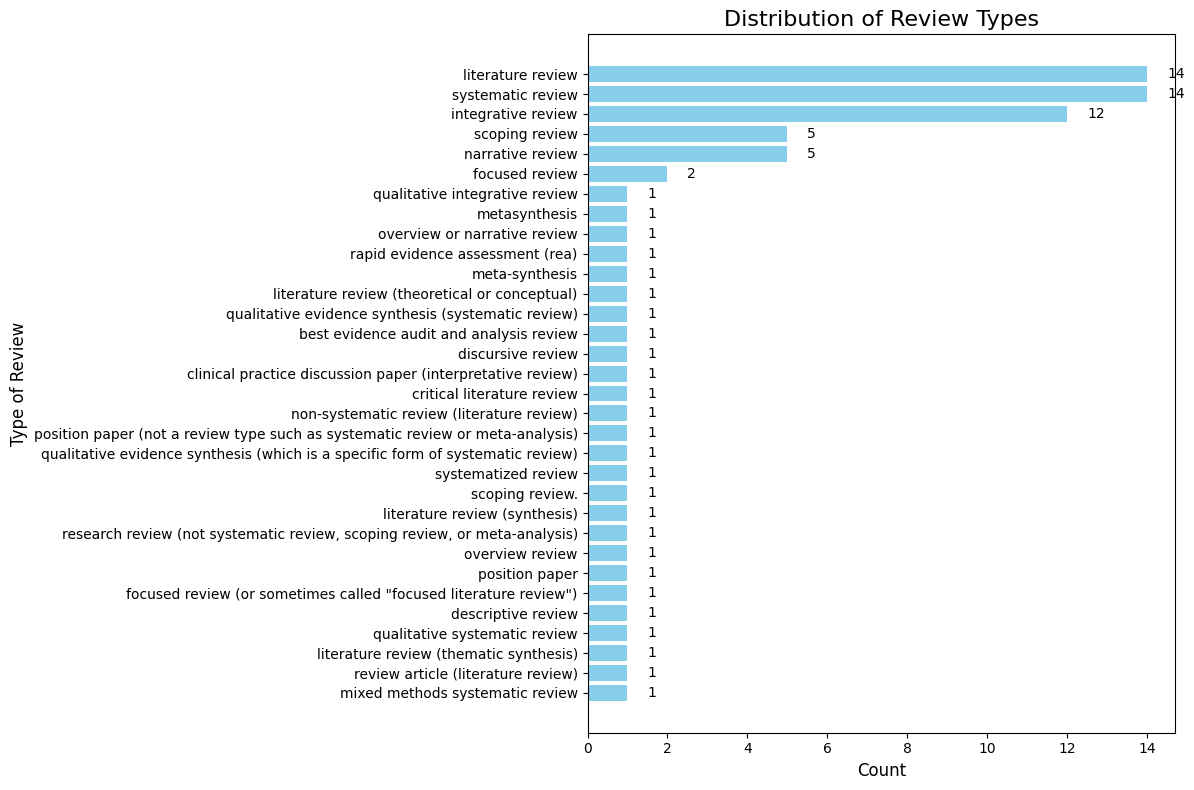

In [163]:
import matplotlib.pyplot as plt

labels = list(result['Cleaned_Type_review'])
counts = list(result['count'])

import matplotlib.pyplot as plt

# Assuming result is a DataFrame
sorted_result = result.sort_values(by='count', ascending=False)

# Create a horizontal bar chart
plt.figure(figsize=(12, 8))
bars = plt.barh(sorted_result['Cleaned_Type_review'], sorted_result['count'], color='skyblue')

# Add numbers to each bar
for bar in bars:
    width = bar.get_width()  # Get the bar width (value of count)
    plt.text(
        width + 0.5,  # Position slightly to the right of the bar
        bar.get_y() + bar.get_height() / 2,  # Position in the middle of the bar
        str(int(width)),  # Convert count to string for display
        va='center',  # Vertical alignment
        fontsize=10  # Font size
    )

# Add labels and title
plt.xlabel('Count', fontsize=12)
plt.ylabel('Type of Review', fontsize=12)
plt.title('Distribution of Review Types', fontsize=16)
plt.gca().invert_yaxis()  # Invert y-axis for descending order
plt.tight_layout()

# Show the plot
plt.show()


In [24]:
import pandas as pd

df= pd.read_csv('updated_decisions_incremental_Type_article.csv')

df

,PubMed ID,DOI,Title,Year,Abstract,Author Keywords,english,Decision,Decision Type,Type_article
0,7567566.0,NaN,Barriers and facilitators of research utilizat...,1995,"For over 20 years, nursing literature has disc...",[],en,**Decision:** included\n\n**Explanation:** \n\...,Included,**Decision:** 0\n\n**Explanation:** The title ...
1,17100863.0,10.1111/j.1365-2753.2006.00632.x,Research utilization and clinical nurse educat...,2006,Clinical nurse educators and other linking age...,[],en,**Included**\n\n**Explanation:**\n- **Inclusio...,Included,**Decision:** 0\n\n**Explanation:** The title ...
2,12470013.0,10.1016/s0964339702000125,Barriers to research utilisation: the clinical...,2002,The advance of the evidence-based practice (EB...,[],en,**Decision:** included\n\n**Explain:** \n\nThe...,Included,**Decision:** 1\n\n**Explanation:** The abstra...
3,18838895.0,10.1097/01.NND.0000320688.57308.f9,Nursing faculty mentors as facilitators for ev...,2008,Increasing use of evidence-based practice (EBP...,[],en,Included\n\nExplain: \n\nThe abstract of the p...,Included,Decision: 1\n\nExplanation: The abstract descr...
4,15913267.0,NaN,Barriers to implementing research in clinical ...,2005,Barriers to implementing research in clinical ...,[],en,**Included**\n\n**Explanation:** \nThe title ...,Included,**Decision:** 0\n\n**Explanation:** The abstra...
...,...,...,...,...,...,...,...,...,...,...
717,22967300.0,10.1111/j.1365-2834.2012.01473.x,Clinical nurses' research capacity in a Norweg...,2012,Aim To examine clinical nurses' research capac...,clinical nurses; competence; research capacity...,en,**Decision:** Included\n\n**Explain:** \n\nThe...,Included,**Decision:** 1\n\n**Explanation:** The abstra...
718,NaN,10.14744/etd.2020.01205,An Academic-Clinical Partnership Project: The ...,2020,Objective: The present study aims to reveal th...,Nurse; scientific research; educational program,en,**Decision:** Included\n\n**Explanation:** \n\...,Included,**Decision:** 1\n\n**Explanation:** The provid...
719,36511161.0,10.7748/nr.2022.e1863,The improvement in research orientation among ...,2023,Background The main barrier to engaging nurses...,best practice; career development; organisatio...,en,**Decision:** Included\n\n**Explain:** \n\n- *...,Included,Decision: 1\n\nExplain: The title explicitly s...
720,26422084.0,10.1111/wvn.12106,The Effectiveness of Interventions for Improvi...,2015,"BackgroundInternationally, a considerable body...",systematic review; research literacy; interven...,en,**Decision:** Included\n\n**Explanation:** \n\...,Included,**Decision:** 0\n\n**Explanation:** The provid...


In [177]:
df_with_decisions[df_with_decisions['Extracted_Number'] != '0'].to_csv("644_not_systematic.csv")

In [179]:
temp = pd.read_csv("label_data/systematics_1 (1).csv")
temp

,Unnamed: 0,PubMed ID,DOI,Title,Year,Abstract,Author Keywords,english,Decision,Decision Type,Type_article,Extracted_Number,Type_review,1\0,Class,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18
0,0,7567566.0,NaN,Barriers and facilitators of research utilizat...,1995,"For over 20 years, nursing literature has disc...",[],en,**Decision:** included\n\n**Explanation:** \n\...,Included,**Decision:** 0\n\n**Explanation:** The title ...,0,Integrative review,1,1,NaN,NaN,NaN,NaN
1,1,17100863.0,10.1111/j.1365-2753.2006.00632.x,Research utilization and clinical nurse educat...,2006,Clinical nurse educators and other linking age...,[],en,**Included**\n\n**Explanation:**\n- **Inclusio...,Included,**Decision:** 0\n\n**Explanation:** The title ...,0,Systematic review,1,1,NaN,NaN,NaN,NaN
2,4,15913267.0,NaN,Barriers to implementing research in clinical ...,2005,Barriers to implementing research in clinical ...,[],en,**Included**\n\n**Explanation:** \nThe title ...,Included,**Decision:** 0\n\n**Explanation:** The abstra...,0,Literature review,1,1,NaN,NaN,NaN,NaN
3,13,10076245.0,10.1097/00002800-199811000-00009,Research utilization and the CNS: confronting ...,1998,Utilization of research in nursing is still in...,[],en,**Decision:** Included\n\n**Explanation:** \n\...,Included,**Decision:** 0\n\n**Explanation:** The abstra...,0,Review of literature,1,1,NaN,NaN,class,0.948718
4,75,8057184.0,10.1111/j.1552-6909.1994.tb01882.x,Research utilization: an overview,1994,"Nursing practice needs to be research based, n...",[],en,Included\n\nExplanation: The abstract indicate...,Included,**Decision:** 0\n\n**Explanation:** The title ...,0,Overview or narrative review,1,1,NaN,NaN,NaN,0.897436
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73,695,10886435.0,10.1046/j.1365-2648.2000.01447.x,Developing the research capacity of department...,2000,The purpose of this literature review is to id...,nursing research; research capacity developmen...,en,**Decision:** included\n\n**Explanation:**\n\n...,Included,**Decision:** 0\n\n**Explanation:** The title ...,0,Literature review,1,1,NaN,NaN,NaN,NaN
74,703,33783388.0,10.1097/ANC.0000000000000851,A Review of the NANN Research Summit Experienc...,2022,Background: The NANN Research Summit has been ...,clinical inquiry; mentorship; neonatal nurse; ...,en,**Decision:** included\n\n**Explanation:** \n\...,Included,**Decision:** 0\n\n**Explanation:** The title ...,0,Descriptive review,0,0,NaN,NaN,NaN,NaN
75,715,34729898.0,10.1111/wvn.12542,The Experiences and Perceptions of Nurses Inte...,2021,Background There is an evidence that some nurs...,nurse education; research education; research ...,en,Included\n\n**Explanation:**\n\n1. **Inclusion...,Included,**Decision:** 0\n\n**Explanation:** The resear...,0,Qualitative Systematic Review,1,1,NaN,NaN,NaN,NaN
76,716,34820932.0,10.1111/jocn.16133,Mixed methods systematic review: Factors influ...,2022,"Aim This study aimed to identify, evaluate and...",barriers and enablers; conducting research; mi...,en,Included\n\n**Explanation:** \n\n- **Inclusion...,Included,**Decision:** 0\n\n**Explanation:** The provid...,0,Mixed methods systematic review,1,1,NaN,NaN,NaN,NaN


In [180]:
temp['Cleaned_Type_review'] = temp['Type_review'].apply(clean_review_type)


In [181]:
result = temp['Cleaned_Type_review'].value_counts()
result = result.reset_index()
result['count'].sum()

78

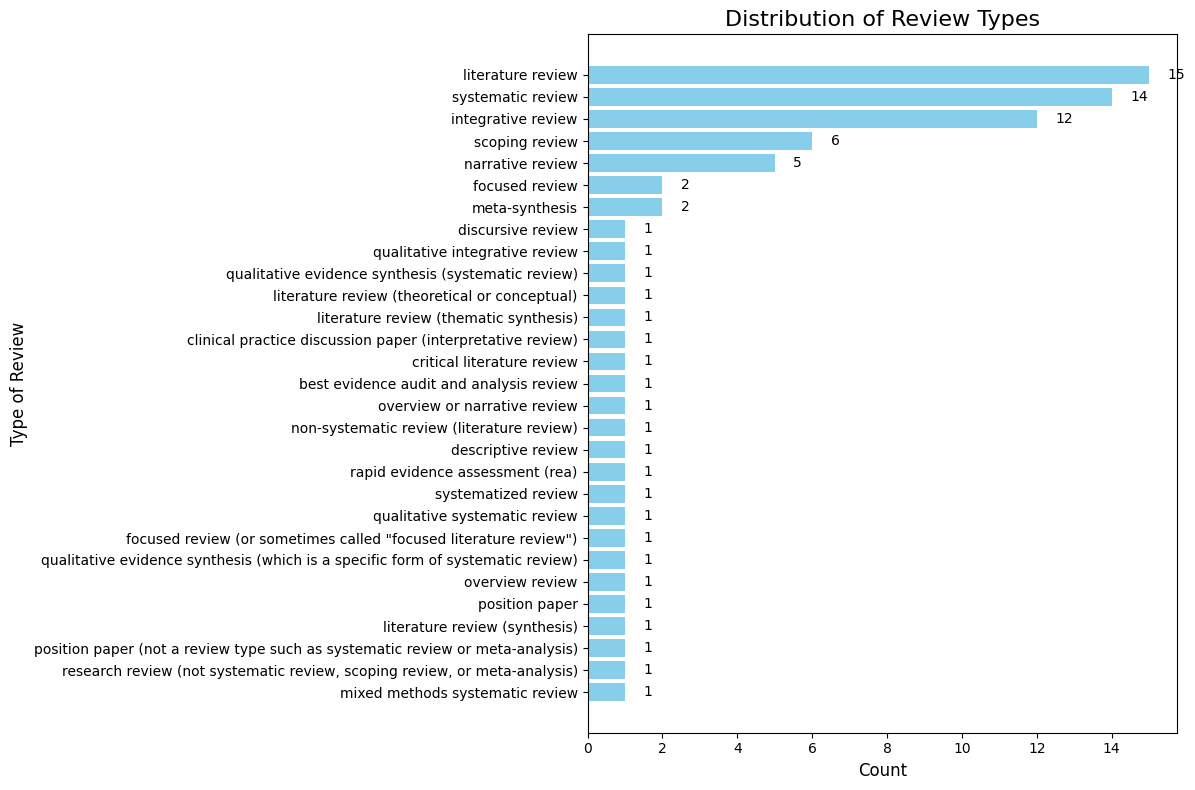

In [182]:
import matplotlib.pyplot as plt

labels = list(result['Cleaned_Type_review'])
counts = list(result['count'])

import matplotlib.pyplot as plt

# Assuming result is a DataFrame
sorted_result = result.sort_values(by='count', ascending=False)

# Create a horizontal bar chart
plt.figure(figsize=(12, 8))
bars = plt.barh(sorted_result['Cleaned_Type_review'], sorted_result['count'], color='skyblue')

# Add numbers to each bar
for bar in bars:
    width = bar.get_width()  # Get the bar width (value of count)
    plt.text(
        width + 0.5,  # Position slightly to the right of the bar
        bar.get_y() + bar.get_height() / 2,  # Position in the middle of the bar
        str(int(width)),  # Convert count to string for display
        va='center',  # Vertical alignment
        fontsize=10  # Font size
    )

# Add labels and title
plt.xlabel('Count', fontsize=12)
plt.ylabel('Type of Review', fontsize=12)
plt.title('Distribution of Review Types', fontsize=16)
plt.gca().invert_yaxis()  # Invert y-axis for descending order
plt.tight_layout()

# Show the plot
plt.show()


In [185]:
import pandas as pd

df_with_decisions= pd.read_csv('final_type_722.csv')

df_with_decisions

,Unnamed: 0,PubMed ID,DOI,Title,Year,Abstract,Author Keywords,english,Decision,Decision Type,Type_article,Extracted_Number
0,0,7567566.0,NaN,Barriers and facilitators of research utilizat...,1995,"For over 20 years, nursing literature has disc...",[],en,**Decision:** included\n\n**Explanation:** \n\...,Included,**Decision:** 0\n\n**Explanation:** The title ...,0
1,1,17100863.0,10.1111/j.1365-2753.2006.00632.x,Research utilization and clinical nurse educat...,2006,Clinical nurse educators and other linking age...,[],en,**Included**\n\n**Explanation:**\n- **Inclusio...,Included,**Decision:** 0\n\n**Explanation:** The title ...,0
2,2,12470013.0,10.1016/s0964339702000125,Barriers to research utilisation: the clinical...,2002,The advance of the evidence-based practice (EB...,[],en,**Decision:** included\n\n**Explain:** \n\nThe...,Included,**Decision:** 1\n\n**Explanation:** The abstra...,1
3,3,18838895.0,10.1097/01.NND.0000320688.57308.f9,Nursing faculty mentors as facilitators for ev...,2008,Increasing use of evidence-based practice (EBP...,[],en,Included\n\nExplain: \n\nThe abstract of the p...,Included,Decision: 1\n\nExplanation: The abstract descr...,1
4,4,15913267.0,NaN,Barriers to implementing research in clinical ...,2005,Barriers to implementing research in clinical ...,[],en,**Included**\n\n**Explanation:** \nThe title ...,Included,**Decision:** 0\n\n**Explanation:** The abstra...,0
...,...,...,...,...,...,...,...,...,...,...,...,...
717,717,22967300.0,10.1111/j.1365-2834.2012.01473.x,Clinical nurses' research capacity in a Norweg...,2012,Aim To examine clinical nurses' research capac...,clinical nurses; competence; research capacity...,en,**Decision:** Included\n\n**Explain:** \n\nThe...,Included,**Decision:** 1\n\n**Explanation:** The abstra...,1
718,718,NaN,10.14744/etd.2020.01205,An Academic-Clinical Partnership Project: The ...,2020,Objective: The present study aims to reveal th...,Nurse; scientific research; educational program,en,**Decision:** Included\n\n**Explanation:** \n\...,Included,**Decision:** 1\n\n**Explanation:** The provid...,1
719,719,36511161.0,10.7748/nr.2022.e1863,The improvement in research orientation among ...,2023,Background The main barrier to engaging nurses...,best practice; career development; organisatio...,en,**Decision:** Included\n\n**Explain:** \n\n- *...,Included,Decision: 1\n\nExplain: The title explicitly s...,1
720,720,26422084.0,10.1111/wvn.12106,The Effectiveness of Interventions for Improvi...,2015,"BackgroundInternationally, a considerable body...",systematic review; research literacy; interven...,en,**Decision:** Included\n\n**Explanation:** \n\...,Included,**Decision:** 0\n\n**Explanation:** The provid...,0


In [187]:
reviews = [
    "systematic review",
    "narrative review",
    "scoping review",
    "meta-analysis",
    "integrative review",
    "literature review",
    "mixed-methods review"
]

In [188]:
import re
from tqdm import tqdm

# Enable tqdm to work with pandas' apply method
tqdm.pandas()

def find_matching_term(description, terms):
    description = str(description).lower()
    for term in terms:
        # Use regex to match whole words only
        pattern = rf'\b{re.escape(term.lower())}\b'
        if re.search(pattern, description):
            return term
    return None

# Apply function to the DataFrame
df_with_decisions['matched_term'] = df_with_decisions['Title'].progress_apply(lambda x: find_matching_term(x, reviews))

df_with_decisions

100%|██████████| 722/722 [00:00<00:00, 22284.02it/s]


,Unnamed: 0,PubMed ID,DOI,Title,Year,Abstract,Author Keywords,english,Decision,Decision Type,Type_article,Extracted_Number,matched_term
0,0,7567566.0,NaN,Barriers and facilitators of research utilizat...,1995,"For over 20 years, nursing literature has disc...",[],en,**Decision:** included\n\n**Explanation:** \n\...,Included,**Decision:** 0\n\n**Explanation:** The title ...,0,integrative review
1,1,17100863.0,10.1111/j.1365-2753.2006.00632.x,Research utilization and clinical nurse educat...,2006,Clinical nurse educators and other linking age...,[],en,**Included**\n\n**Explanation:**\n- **Inclusio...,Included,**Decision:** 0\n\n**Explanation:** The title ...,0,systematic review
2,2,12470013.0,10.1016/s0964339702000125,Barriers to research utilisation: the clinical...,2002,The advance of the evidence-based practice (EB...,[],en,**Decision:** included\n\n**Explain:** \n\nThe...,Included,**Decision:** 1\n\n**Explanation:** The abstra...,1,None
3,3,18838895.0,10.1097/01.NND.0000320688.57308.f9,Nursing faculty mentors as facilitators for ev...,2008,Increasing use of evidence-based practice (EBP...,[],en,Included\n\nExplain: \n\nThe abstract of the p...,Included,Decision: 1\n\nExplanation: The abstract descr...,1,None
4,4,15913267.0,NaN,Barriers to implementing research in clinical ...,2005,Barriers to implementing research in clinical ...,[],en,**Included**\n\n**Explanation:** \nThe title ...,Included,**Decision:** 0\n\n**Explanation:** The abstra...,0,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...
717,717,22967300.0,10.1111/j.1365-2834.2012.01473.x,Clinical nurses' research capacity in a Norweg...,2012,Aim To examine clinical nurses' research capac...,clinical nurses; competence; research capacity...,en,**Decision:** Included\n\n**Explain:** \n\nThe...,Included,**Decision:** 1\n\n**Explanation:** The abstra...,1,None
718,718,NaN,10.14744/etd.2020.01205,An Academic-Clinical Partnership Project: The ...,2020,Objective: The present study aims to reveal th...,Nurse; scientific research; educational program,en,**Decision:** Included\n\n**Explanation:** \n\...,Included,**Decision:** 1\n\n**Explanation:** The provid...,1,None
719,719,36511161.0,10.7748/nr.2022.e1863,The improvement in research orientation among ...,2023,Background The main barrier to engaging nurses...,best practice; career development; organisatio...,en,**Decision:** Included\n\n**Explain:** \n\n- *...,Included,Decision: 1\n\nExplain: The title explicitly s...,1,None
720,720,26422084.0,10.1111/wvn.12106,The Effectiveness of Interventions for Improvi...,2015,"BackgroundInternationally, a considerable body...",systematic review; research literacy; interven...,en,**Decision:** Included\n\n**Explanation:** \n\...,Included,**Decision:** 0\n\n**Explanation:** The provid...,0,systematic review


In [189]:
df_with_decisions.matched_term.value_counts()

matched_term
systematic review     15
integrative review    11
literature review      6
scoping review         2
narrative review       1
Name: count, dtype: int64

In [191]:
df_with_decisions[df_with_decisions['matched_term'] == 'systematic review'].Title.tolist()

['Research utilization and clinical nurse educators: A systematic review',
 'Barriers and facilitators of nursing research utilization in Iran: A systematic review',
 "The Importance of Context and Organization Culture in the Understanding of Nurses' Barriers Against Research Utilization: A Systematic Review",
 'Barriers to Research Utilization in Nursing: A Systematic Review (2002-2021)',
 'Barriers Associated With Evidence-Based Practice Among Nurses in Low- and Middle-Income Countries: A Systematic Review',
 'The Experience and Effectiveness of Nurse Practitioners in Orthopaedic Settings: A Comprehensive Systematic Review',
 'A systematic review of the barriers, enablers and strategies to embedding translational research within the public hospital system focusing on nursing and allied health professions',
 'Interventions to enhance the research productivity of academic staff in higher education schools of nursing: A systematic review',
 'Perceived barriers and enablers of nursing re